# Global Pollution Analysis and Energy Recovery

## Objective
To analyze pollution and energy-related data, group similar observations using clustering, and predict energy recovery using a feedforward neural network.

**Methods:** K-Means, Hierarchical Clustering, Linear Regression and Neural Network.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")


Libraries loaded successfully.


In [2]:
# Put Global_Pollution_Analysis.csv in the same folder as this notebook.
files = [f for f in os.listdir(".") if f.lower().endswith(".csv")]
preferred_names = [
    "Global_Pollution_Analysis(4).csv",
    "Global_Pollution_Analysis.csv"
]
file_path = next((f for f in preferred_names if f in files), None)

if file_path is None:
    preferred = [f for f in files if "global_pollution_analysis" in f.lower()]
    if len(preferred) == 1:
        file_path = preferred[0]
    else:
        raise FileNotFoundError(
            "Global_Pollution_Analysis.csv was not found. Put the correct CSV beside this notebook."
        )

df = pd.read_csv(file_path)
print("Dataset:", file_path)
print("Shape:", df.shape)
display(df.head())


Dataset: Global_Pollution_Analysis(4).csv
Shape: (200, 13)


,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


In [3]:
print("Columns:")
print(df.columns.tolist())
print("\nMissing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))


Columns:
['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index', 'Soil_Pollution_Index', 'Industrial_Waste (in tons)', 'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)', 'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)', 'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)', 'GDP_Per_Capita (in USD)']

Missing values: 0
Duplicate rows: 0


## 1. Data Preprocessing

In [4]:
df = df.copy()
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    mode = df[col].mode(dropna=True)
    df[col] = df[col].fillna(mode.iloc[0] if not mode.empty else "Unknown")

df = df.drop_duplicates().reset_index(drop=True)
print("Cleaning completed.")
print("Rows:", len(df))
print("Remaining missing values:", int(df.isnull().sum().sum()))


Cleaning completed.
Rows: 200
Remaining missing values: 0


## 2. Feature Engineering

In [5]:
expected = [
    "Country","Year","Air_Pollution_Index","Water_Pollution_Index",
    "Soil_Pollution_Index","Industrial_Waste (in tons)",
    "Energy_Recovered (in GWh)","CO2_Emissions (in MT)",
    "Renewable_Energy (%)","Plastic_Waste_Produced (in tons)",
    "Energy_Consumption_Per_Capita (in MWh)",
    "Population (in millions)","GDP_Per_Capita (in USD)"
]
missing = [c for c in expected if c not in df.columns]
if missing:
    raise ValueError("Missing expected columns: " + str(missing))

pollution = ["Air_Pollution_Index","Water_Pollution_Index","Soil_Pollution_Index"]
df["Pollution_Index"] = df[pollution].mean(axis=1)

# The supplied dataset already has energy consumption per capita.
# This feature gives an estimated total in MWh.
df["Estimated_Total_Energy_Consumption_MWh"] = (
    df["Energy_Consumption_Per_Capita (in MWh)"] *
    df["Population (in millions)"] * 1_000_000
)

country_map = {x:i for i,x in enumerate(sorted(df["Country"].astype(str).unique()))}
df["Country_Label"] = df["Country"].astype(str).map(country_map)
df["Year_Label"] = pd.to_numeric(df["Year"], errors="coerce").astype(int)

yearly = df.groupby("Year", as_index=False).agg({
    "Air_Pollution_Index":"mean",
    "Water_Pollution_Index":"mean",
    "Soil_Pollution_Index":"mean",
    "Industrial_Waste (in tons)":"mean",
    "Energy_Recovered (in GWh)":"mean"
})
print("Feature engineering completed.")
display(df[["Country","Year","Pollution_Index","Energy_Recovered (in GWh)"]].head())


Feature engineering completed.


,Country,Year,Pollution_Index,Energy_Recovered (in GWh)
0,Hungary,2005,149.640000,158.14
1,Singapore,2001,88.093333,498.04
2,Romania,2016,98.890000,489.51
3,Cook Islands,2018,147.116667,145.18
4,Djibouti,2008,142.746667,40.38


## 3. Exploratory Data Analysis

In [6]:
display(df[pollution + [
    "Industrial_Waste (in tons)",
    "Energy_Recovered (in GWh)",
    "CO2_Emissions (in MT)"
]].describe().round(2))


,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT)
count,200.00,200.00,200.00,200.00,200.00,200.00
mean,180.63,115.07,76.49,52891.68,260.45,24.88
std,67.07,47.58,39.69,27224.49,147.14,14.47
min,50.30,31.13,11.15,1019.37,11.73,1.92
25%,134.97,74.55,40.89,31201.97,118.35,11.22
50%,183.38,112.30,78.60,55299.15,273.14,25.36
75%,237.42,157.48,109.21,74805.82,384.96,38.55
max,297.95,199.32,149.23,99739.36,499.98,49.69


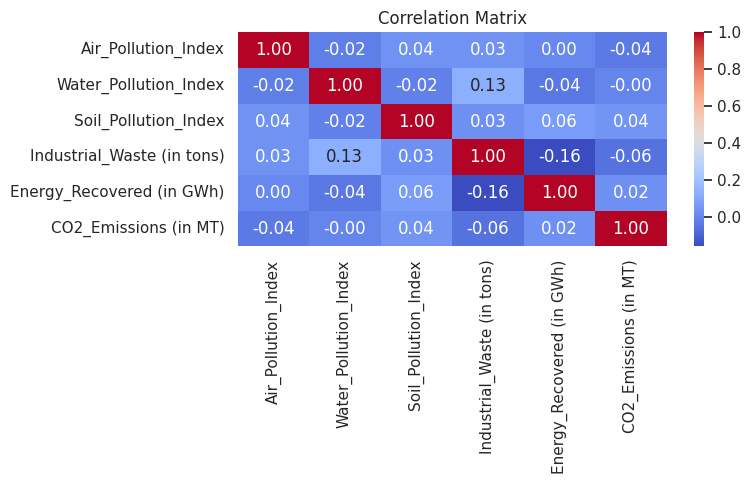

In [7]:
plt.figure(figsize=(8,5))
sns.heatmap(df[pollution + [
    "Industrial_Waste (in tons)","Energy_Recovered (in GWh)",
    "CO2_Emissions (in MT)"
]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


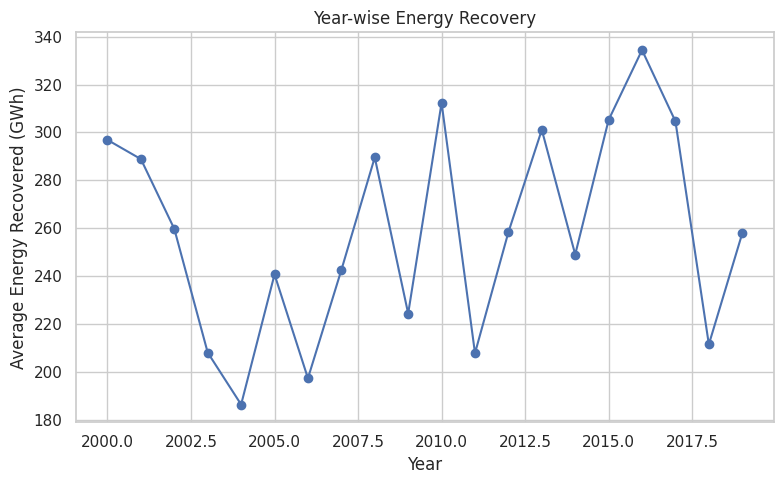

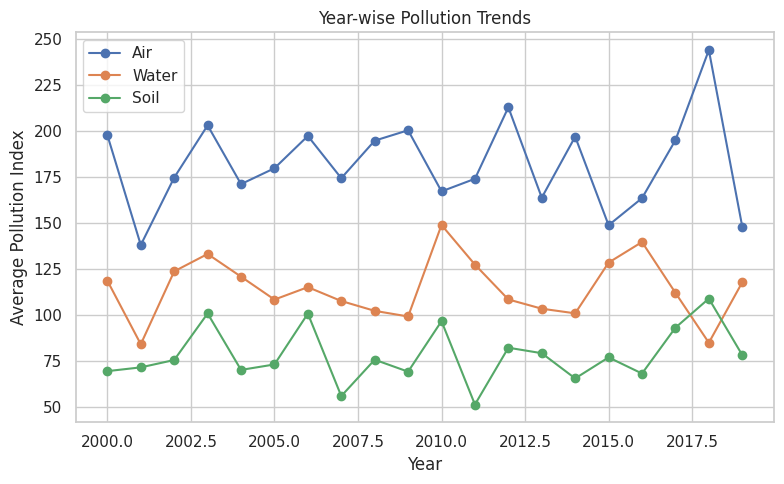

In [8]:
plt.figure(figsize=(8,5))
plt.plot(yearly["Year"], yearly["Energy_Recovered (in GWh)"], marker="o")
plt.xlabel("Year"); plt.ylabel("Average Energy Recovered (GWh)")
plt.title("Year-wise Energy Recovery")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
plt.plot(yearly["Year"], yearly["Air_Pollution_Index"], marker="o", label="Air")
plt.plot(yearly["Year"], yearly["Water_Pollution_Index"], marker="o", label="Water")
plt.plot(yearly["Year"], yearly["Soil_Pollution_Index"], marker="o", label="Soil")
plt.xlabel("Year"); plt.ylabel("Average Pollution Index")
plt.title("Year-wise Pollution Trends")
plt.legend(); plt.tight_layout(); plt.show()


## 4. K-Means Clustering

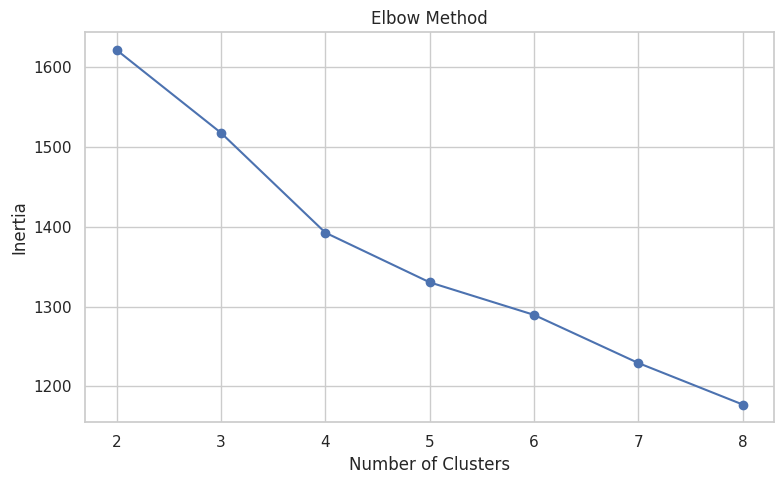

,Countries,Avg_Pollution,Avg_Energy_Recovered
KMeans_Cluster,,,
0,88,117.45,298.70
1,64,127.46,223.30
2,48,131.66,239.85


In [9]:
cluster_cols = [
    "Air_Pollution_Index","Water_Pollution_Index","Soil_Pollution_Index",
    "Industrial_Waste (in tons)","Energy_Recovered (in GWh)",
    "CO2_Emissions (in MT)","Renewable_Energy (%)",
    "Plastic_Waste_Produced (in tons)",
    "Energy_Consumption_Per_Capita (in MWh)"
]
C = df[cluster_cols].astype(float)
mu, sigma = C.mean(), C.std(ddof=0).replace(0,1)
C_scaled = ((C-mu)/sigma).to_numpy()

def kmeans(X, k, seed=42, max_iter=100):
    X=np.asarray(X,float); rng=np.random.default_rng(seed)
    centers=X[rng.choice(len(X),k,replace=False)].copy()
    labels=np.zeros(len(X),dtype=int)
    for _ in range(max_iter):
        d=((X[:,None,:]-centers[None,:,:])**2).sum(axis=2)
        new_labels=d.argmin(axis=1)
        new_centers=centers.copy()
        for j in range(k):
            pts=X[new_labels==j]
            new_centers[j]=pts.mean(axis=0) if len(pts) else X[rng.integers(len(X))]
        if np.array_equal(labels,new_labels) and np.allclose(centers,new_centers):
            break
        labels,centers=new_labels,new_centers
    inertia=float(((X-centers[labels])**2).sum())
    return labels,centers,inertia

ks=range(2,9)
inertias=[kmeans(C_scaled,k)[2] for k in ks]
plt.figure(figsize=(8,5))
plt.plot(list(ks),inertias,marker="o")
plt.xlabel("Number of Clusters"); plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(ks)); plt.tight_layout(); plt.show()

best_k=3
df["KMeans_Cluster"]=kmeans(C_scaled,best_k)[0]
display(df.groupby("KMeans_Cluster").agg(
    Countries=("Country","count"),
    Avg_Pollution=("Pollution_Index","mean"),
    Avg_Energy_Recovered=("Energy_Recovered (in GWh)","mean")
).round(2))


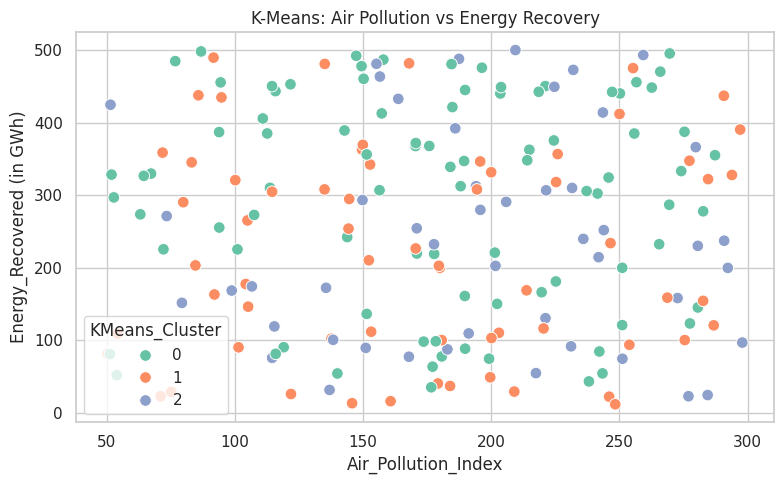

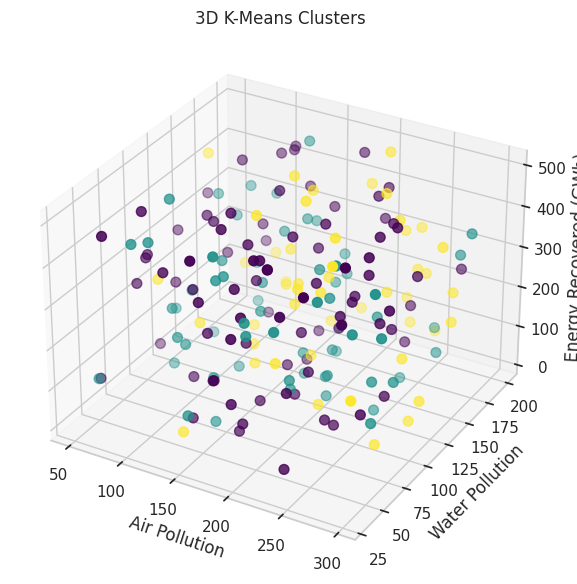

In [10]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="Air_Pollution_Index",y="Energy_Recovered (in GWh)",
                hue="KMeans_Cluster",palette="Set2",s=70)
plt.title("K-Means: Air Pollution vs Energy Recovery")
plt.tight_layout(); plt.show()

fig=plt.figure(figsize=(9,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(df["Air_Pollution_Index"],df["Water_Pollution_Index"],
           df["Energy_Recovered (in GWh)"],c=df["KMeans_Cluster"],cmap="viridis",s=50)
ax.set_xlabel("Air Pollution"); ax.set_ylabel("Water Pollution")
ax.set_zlabel("Energy Recovered (GWh)")
ax.set_title("3D K-Means Clusters")
plt.tight_layout(); plt.show()


## 5. Hierarchical Clustering

In [11]:
def agglomerative_average(X, n_clusters=3):
    X=np.asarray(X,float)
    clusters=[[i] for i in range(len(X))]
    history=[]
    next_id=len(X)
    def dist(a,b):
        A=X[a]; B=X[b]
        return np.sqrt(((A[:,None,:]-B[None,:,:])**2).sum(axis=2)).mean()
    while len(clusters)>n_clusters:
        best=(None,None,np.inf)
        for i in range(len(clusters)):
            for j in range(i+1,len(clusters)):
                d=dist(clusters[i],clusters[j])
                if d<best[2]: best=(i,j,d)
        i,j,d=best
        merged=clusters[i]+clusters[j]
        history.append((clusters[i],clusters[j],d,len(merged)))
        clusters.pop(j); clusters.pop(i); clusters.append(merged)
        next_id+=1
    labels=np.empty(len(X),dtype=int)
    for lab,members in enumerate(clusters): labels[members]=lab
    return labels,history

hier_labels, _ = agglomerative_average(C_scaled,best_k)
df["Hierarchical_Cluster"]=hier_labels
display(df.groupby("Hierarchical_Cluster").agg(
    Countries=("Country","count"),
    Avg_Pollution=("Pollution_Index","mean"),
    Avg_Energy_Recovered=("Energy_Recovered (in GWh)","mean")
).round(2))


,Countries,Avg_Pollution,Avg_Energy_Recovered
Hierarchical_Cluster,,,
0,1,187.04,390.35
1,9,125.94,348.10
2,190,123.64,255.61


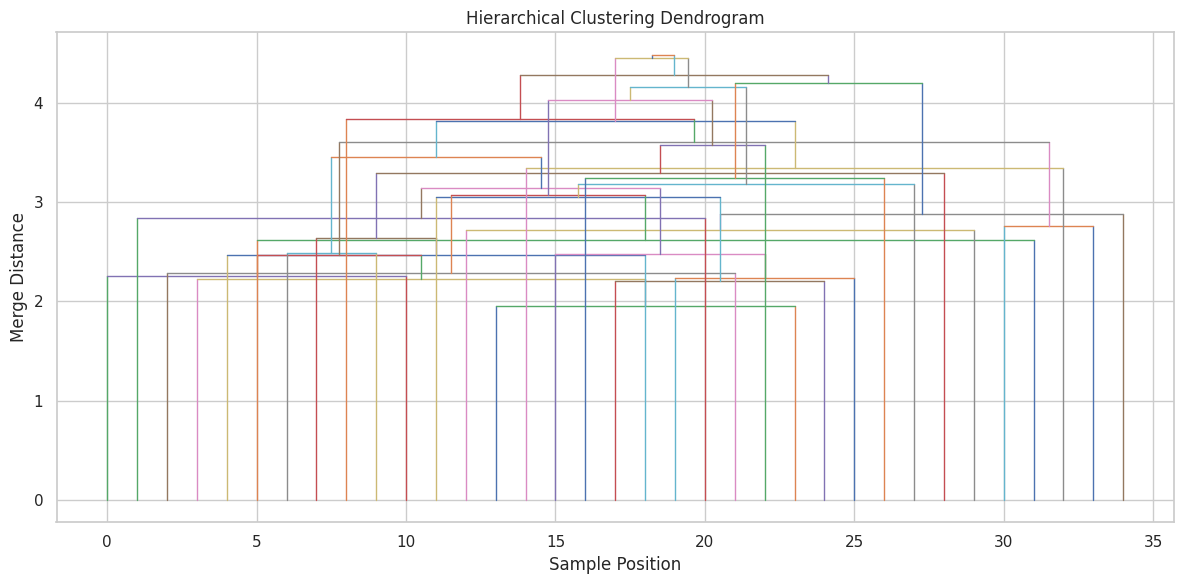

In [12]:
# Dendrogram on a small sample for readability.
sample_n=min(35,len(df))
sample_idx=np.linspace(0,len(df)-1,sample_n,dtype=int)
_, history=agglomerative_average(C_scaled[sample_idx],1)

# Build a standard dendrogram layout from the merge history.
pos={i:float(i) for i in range(sample_n)}
height={i:0.0 for i in range(sample_n)}
node_id={i:i for i in range(sample_n)}
next_id=sample_n
fig,ax=plt.subplots(figsize=(12,6))

for left,right,h,size in history:
    left_nodes=set(node_id[i] for i in left)
    right_nodes=set(node_id[i] for i in right)
    lx=np.mean([pos[n] for n in left_nodes])
    rx=np.mean([pos[n] for n in right_nodes])
    lh=max(height[n] for n in left_nodes)
    rh=max(height[n] for n in right_nodes)
    ax.plot([lx,lx],[lh,h],linewidth=1)
    ax.plot([rx,rx],[rh,h],linewidth=1)
    ax.plot([lx,rx],[h,h],linewidth=1)
    pos[next_id]=(lx+rx)/2
    height[next_id]=h
    for i in left+right: node_id[i]=next_id
    next_id+=1

ax.set_title("Hierarchical Clustering Dendrogram")
ax.set_xlabel("Sample Position"); ax.set_ylabel("Merge Distance")
plt.tight_layout(); plt.show()


## 6. Prepare Prediction Data

In [13]:
features=[
    "Air_Pollution_Index","Water_Pollution_Index","Soil_Pollution_Index",
    "Industrial_Waste (in tons)","CO2_Emissions (in MT)",
    "Renewable_Energy (%)","Plastic_Waste_Produced (in tons)",
    "Energy_Consumption_Per_Capita (in MWh)",
    "Population (in millions)","GDP_Per_Capita (in USD)","Year"
]
target="Energy_Recovered (in GWh)"

X=df[features].astype(float).to_numpy()
y=df[target].astype(float).to_numpy()

rng=np.random.default_rng(42)
idx=np.arange(len(df)); rng.shuffle(idx)
cut=int(.8*len(idx))
tr,te=idx[:cut],idx[cut:]
Xtr_raw,Xte_raw=X[tr],X[te]
ytr,yte=y[tr],y[te]

xmean=Xtr_raw.mean(0); xstd=Xtr_raw.std(0); xstd[xstd==0]=1
Xtr=(Xtr_raw-xmean)/xstd
Xte=(Xte_raw-xmean)/xstd

def metrics(y_true,pred):
    mse=float(np.mean((y_true-pred)**2))
    mae=float(np.mean(np.abs(y_true-pred)))
    ss_res=float(np.sum((y_true-pred)**2))
    ss_tot=float(np.sum((y_true-y_true.mean())**2))
    r2=1-ss_res/ss_tot if ss_tot else 0.0
    return r2,mse,mae

print("Training rows:",len(Xtr),"Testing rows:",len(Xte))


Training rows: 160 Testing rows: 40


## 7. Linear Regression Baseline

In [14]:
A=np.column_stack([np.ones(len(Xtr)),Xtr])
B=np.column_stack([np.ones(len(Xte)),Xte])
I=np.eye(A.shape[1]); I[0,0]=0
w=np.linalg.solve(A.T@A+1e-8*I,A.T@ytr)
lin_pred=B@w
lin_r2,lin_mse,lin_mae=metrics(yte,lin_pred)

print("Linear Regression")
print("R2 :",round(lin_r2,4))
print("MSE:",round(lin_mse,4))
print("MAE:",round(lin_mae,4))


Linear Regression
R2 : -0.1436
MSE: 23527.4818
MAE: 134.8496


## 8. Feedforward Neural Network

In [15]:
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    TF_OK=True
    print("TensorFlow/Keras available.")
except Exception:
    TF_OK=False
    print("TensorFlow/Keras not available. NumPy neural-network fallback will be used.")


TensorFlow/Keras not available. NumPy neural-network fallback will be used.


In [16]:
# Keep a validation part of the training data.
val_n=max(1,int(.2*len(Xtr)))
Xfit,yfit=Xtr[:-val_n],ytr[:-val_n]
Xval,yval=Xtr[-val_n:],ytr[-val_n:]

def numpy_nn_train(X,y,Xv,yv,h1=32,h2=16,lr=.001,epochs=300,seed=42):
    rng=np.random.default_rng(seed)
    ym,ys=y.mean(),y.std() or 1.0
    yy=(y-ym)/ys; yyv=(yv-ym)/ys
    W1=rng.normal(0,np.sqrt(2/X.shape[1]),(X.shape[1],h1)); b1=np.zeros(h1)
    W2=rng.normal(0,np.sqrt(2/h1),(h1,h2)); b2=np.zeros(h2)
    W3=rng.normal(0,np.sqrt(2/h2),(h2,1)); b3=np.zeros(1)
    loss=[]; val_loss=[]
    relu=lambda z:np.maximum(0,z)
    for _ in range(epochs):
        z1=X@W1+b1; a1=relu(z1)
        z2=a1@W2+b2; a2=relu(z2)
        p=(a2@W3+b3).ravel()
        e=p-yy; dp=2*e[:,None]/len(X)
        dW3=a2.T@dp; db3=dp.sum(0)
        dz2=(dp@W3.T)*(z2>0); dW2=a1.T@dz2; db2=dz2.sum(0)
        dz1=(dz2@W2.T)*(z1>0); dW1=X.T@dz1; db1=dz1.sum(0)
        W1-=lr*dW1; b1-=lr*db1; W2-=lr*dW2; b2-=lr*db2; W3-=lr*dW3; b3-=lr*db3
        vp=(relu(relu(Xv@W1+b1)@W2+b2)@W3+b3).ravel()
        loss.append(float(np.mean(e**2))); val_loss.append(float(np.mean((vp-yyv)**2)))
    def predict(Z):
        return (relu(relu(Z@W1+b1)@W2+b2)@W3+b3).ravel()*ys+ym
    return predict,{"loss":loss,"val_loss":val_loss}

if TF_OK:
    tf.random.set_seed(42)
    nn=keras.Sequential([
        layers.Input(shape=(Xfit.shape[1],)),
        layers.Dense(32,activation="relu"),
        layers.Dense(16,activation="relu"),
        layers.Dense(1,activation="linear")
    ])
    nn.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),loss="mse",metrics=["mae"])
    hist=nn.fit(Xfit,yfit,validation_data=(Xval,yval),epochs=100,batch_size=16,verbose=0)
    nn_pred=nn.predict(Xte,verbose=0).ravel()
    history=hist.history
else:
    predict,history=numpy_nn_train(Xfit,yfit,Xval,yval)
    nn_pred=predict(Xte)

nn_r2,nn_mse,nn_mae=metrics(yte,nn_pred)
print("Neural Network")
print("R2 :",round(nn_r2,4))
print("MSE:",round(nn_mse,4))
print("MAE:",round(nn_mae,4))


Neural Network
R2 : -0.3385
MSE: 27538.498
MAE: 145.8823


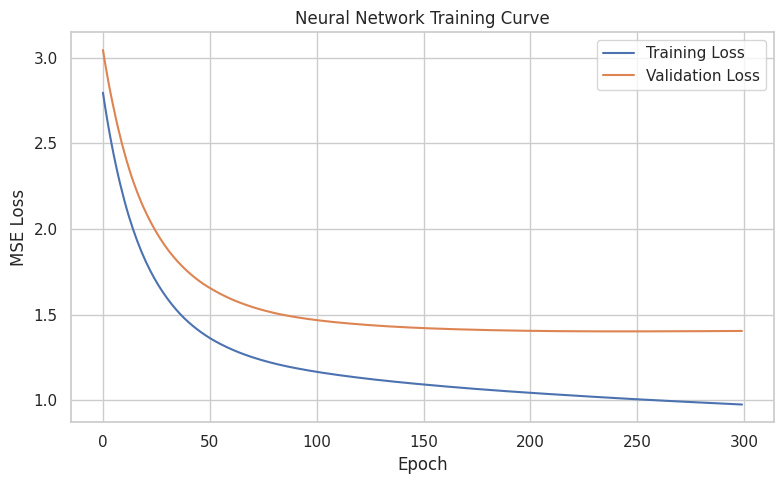

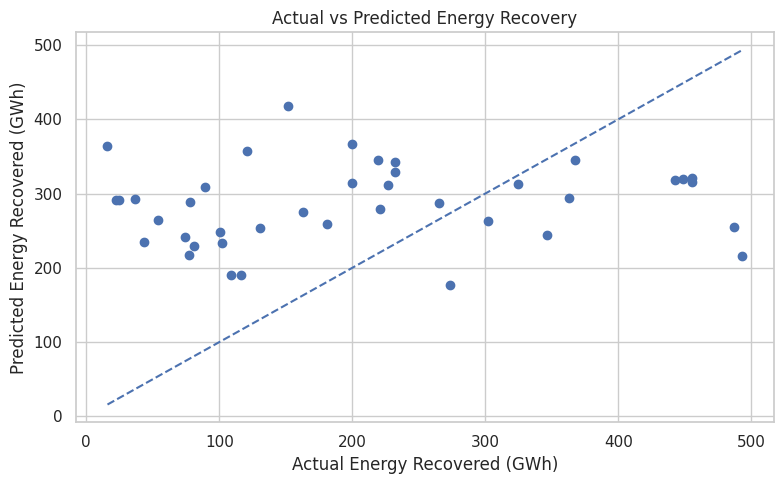

In [17]:
plt.figure(figsize=(8,5))
plt.plot(history["loss"],label="Training Loss")
plt.plot(history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss")
plt.title("Neural Network Training Curve")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
plt.scatter(yte,nn_pred)
lo=min(yte.min(),nn_pred.min()); hi=max(yte.max(),nn_pred.max())
plt.plot([lo,hi],[lo,hi],"--")
plt.xlabel("Actual Energy Recovered (GWh)")
plt.ylabel("Predicted Energy Recovered (GWh)")
plt.title("Actual vs Predicted Energy Recovery")
plt.tight_layout(); plt.show()


## 9. Simple Hyperparameter Tuning

In [18]:
configs=[
    (16,8,.001),
    (32,16,.001),
    (32,16,.0005)
]
tuning=[]

for h1,h2,lr in configs:
    if TF_OK:
        tf.random.set_seed(42)
        m=keras.Sequential([
            layers.Input(shape=(Xfit.shape[1],)),
            layers.Dense(h1,activation="relu"),
            layers.Dense(h2,activation="relu"),
            layers.Dense(1,activation="linear")
        ])
        m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),loss="mse")
        m.fit(Xfit,yfit,validation_data=(Xval,yval),epochs=75,batch_size=16,verbose=0)
        p=m.predict(Xte,verbose=0).ravel()
    else:
        f,_=numpy_nn_train(Xfit,yfit,Xval,yval,h1,h2,lr,200)
        p=f(Xte)
    r,mse,mae=metrics(yte,p)
    tuning.append([f"{h1}-{h2}",lr,r,mse,mae])

tuning_df=pd.DataFrame(tuning,columns=["Hidden Neurons","Learning Rate","R2","MSE","MAE"])
display(tuning_df.round(4))


,Hidden Neurons,Learning Rate,R2,MSE,MAE
0,16-8,0.0010,-0.7689,36393.5752,155.0589
1,32-16,0.0010,-0.3522,27819.4461,146.4139
2,32-16,0.0005,-0.3244,27247.4872,142.6871


## 10. Model Comparison and Final Results

,Model,R2,MSE,MAE
0,Linear Regression,-0.1436,23527.4818,134.8496
1,Neural Network,-0.3385,27538.4980,145.8823


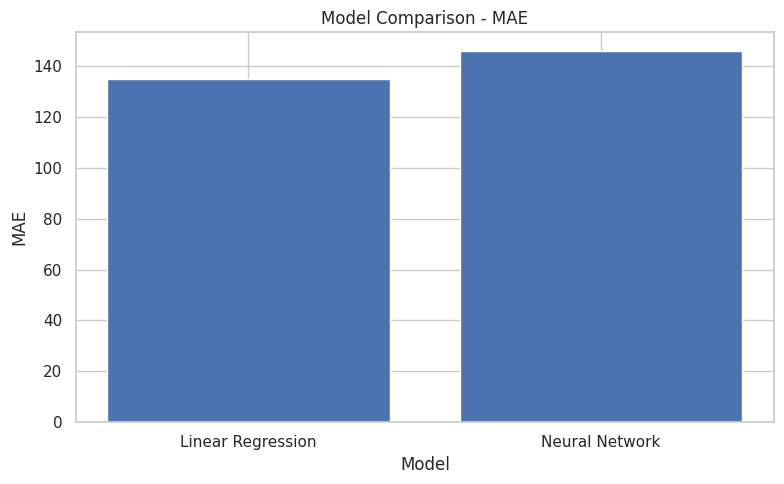


Project summary
Observations: 200
Countries: 175
K-Means clusters: 3
Average energy recovered (GWh): 260.45
Best K-Means cluster by average energy recovery: 0


In [19]:
results=pd.DataFrame({
    "Model":["Linear Regression","Neural Network"],
    "R2":[lin_r2,nn_r2],
    "MSE":[lin_mse,nn_mse],
    "MAE":[lin_mae,nn_mae]
})
display(results.round(4))

plt.figure(figsize=(8,5))
plt.bar(results["Model"], results["MAE"])
plt.xlabel("Model")
plt.ylabel("MAE")
plt.title("Model Comparison - MAE")
plt.tight_layout(); plt.show()

print("\nProject summary")
print("Observations:",len(df))
print("Countries:",df["Country"].nunique())
print("K-Means clusters:",best_k)
print("Average energy recovered (GWh):",round(df[target].mean(),2))
print("Best K-Means cluster by average energy recovery:",
      int(df.groupby("KMeans_Cluster")[target].mean().idxmax()))


In [20]:
output="Global_Pollution_Analysis_Final_Processed.csv"
df.to_csv(output,index=False)
print("Processed dataset saved as:",output)

print("\nPROJECT COMPLETED SUCCESSFULLY")


Processed dataset saved as: Global_Pollution_Analysis_Final_Processed.csv

PROJECT COMPLETED SUCCESSFULLY
